# Phần 1.3 — JustWatch: thị trường streaming hợp pháp

Phần này dùng mục *watch providers* trong cùng các lần gọi **TMDb API** ở phần 1.2 — TMDb lấy dữ liệu này từ **JustWatch** (theo điều khoản phải ghi nguồn JustWatch). Với mỗi phim, ở mỗi nước, phim đang có trên dịch vụ nào và theo hình thức nào (**thuê bao**, **miễn phí**, **miễn phí có quảng cáo**, **thuê lẻ**, **mua**). Bảng `data_clean/tmdb_watch_providers.parquet`: ~8,6 triệu dòng, 139 nước, ~780 dịch vụ.

Lưu ý: đây là **ảnh chụp hiện tại (2026)**, không có lịch sử; chỉ tính các phim trong tập phim của dự án (~104k phim có dữ liệu). Tên dịch vụ được gộp về thương hiệu ("Netflix Standard with Ads" → Netflix); các "kênh" bán kèm qua nền tảng khác ("... Amazon Channel") bị bỏ để không đếm trùng. Biểu đồ lưu vào `plots/3_tmdb_streaming/`.

In [1]:
# Tìm thư mục gốc dự án (chứa src/viz_style.py) để import phong cách biểu đồ dùng chung
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "viz_style.py").exists())
sys.path.insert(0, str(ROOT / "src"))
%matplotlib inline

## Nạp dữ liệu

In [2]:
import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter

import viz_style as V

V.setup()
FOLDER = "3_tmdb_streaming"
SRC = "Nguồn: TMDb API (2026), dữ liệu streaming do JustWatch cung cấp."

wp = duckdb.sql(f"SELECT * FROM read_parquet('{(V.DC / 'tmdb_watch_providers.parquet').as_posix()}')").df()
genres = duckdb.sql(f"""SELECT tconst AS imdb_id, genres FROM read_parquet('{(V.DC / 'imdb_movies_all.parquet').as_posix()}')""").df()


def brand(p):
    """Gộp các biến thể tên ("Netflix Standard with Ads", "Disney Plus"...) về một thương hiệu.
    Kênh bổ sung bán qua nền tảng khác ("... Amazon Channel") bị bỏ để không đếm trùng."""
    l = p.lower()
    if "channel" in l:
        return None
    for key, name in [("netflix", "Netflix"), ("prime video", "Prime Video"), ("amazon prime", "Prime Video"),
                      ("disney", "Disney+"), ("hbo max", "Max"), ("hulu", "Hulu"), ("peacock", "Peacock"),
                      ("paramount", "Paramount+"), ("apple tv", "Apple TV+"), ("mubi", "MUBI")]:
        if key in l:
            return name
    return "Max" if l in ("max", "max with ads") else p


wp["brand"] = wp["provider"].map(brand)
sub = wp[wp["kind"].isin(["flatrate", "free", "ads"]) & wp["brand"].notna()]   # xem không cần mua/thuê lẻ
n_movies = wp["imdb_id"].nunique()
print(f"{len(wp):,} dòng; {n_movies:,} phim; {wp['country'].nunique()} nước; {wp['provider'].nunique()} dịch vụ")

8,638,740 dòng; 103,769 phim; 139 nước; 783 dịch vụ


## 1. Ở đâu xem được nhiều phim hợp pháp nhất?

  wrote plots\3_tmdb_streaming\01_world_catalog_map.png


WindowsPath('D:/dulieulon/plots/3_tmdb_streaming/01_world_catalog_map.png')

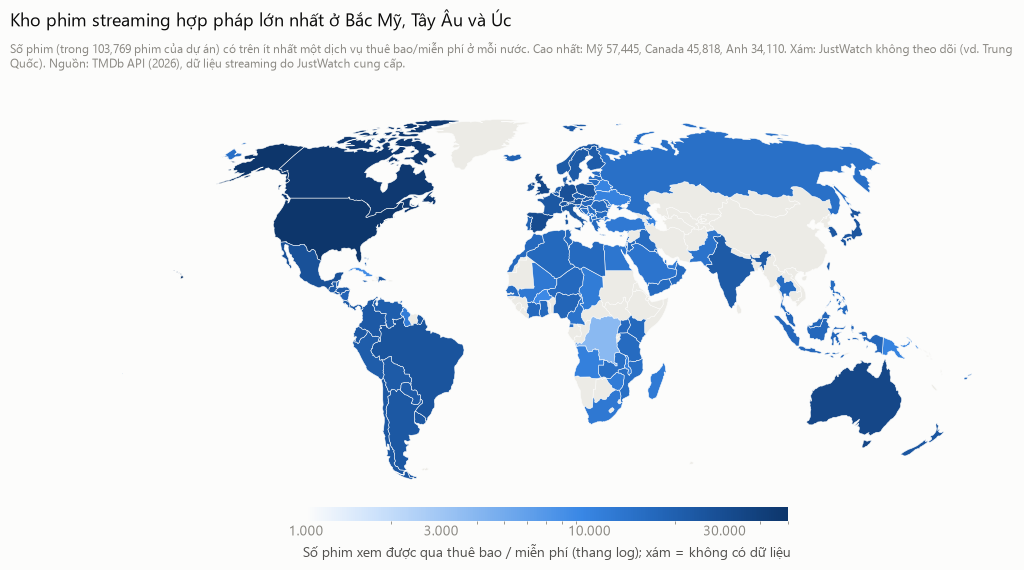

In [3]:
per_country = sub.groupby("country")["imdb_id"].nunique()
world = gpd.read_file(V.ROOT / "data_raw/geo/ne_110m_admin_0_countries.geojson")
world = world[world["ISO_A2_EH"] != "AQ"].to_crs("+proj=robin")
world["movies"] = world["ISO_A2_EH"].map(per_country)
fig, ax = plt.subplots(figsize=(11, 6))
ax.axis("off")
world[world["movies"].isna()].plot(ax=ax, color="#ecebe6", edgecolor=V.SURFACE, linewidth=0.4)
world.dropna(subset=["movies"]).plot(ax=ax, column="movies", cmap=V.SEQ, norm=LogNorm(1000, 50000),
                                    edgecolor=V.SURFACE, linewidth=0.4)
sm = plt.cm.ScalarMappable(cmap=V.SEQ, norm=LogNorm(1000, 50000))
cb = fig.colorbar(sm, ax=ax, orientation="horizontal", shrink=0.45, pad=0.02, aspect=35)
cb.outline.set_visible(False)
cb.set_ticks([1000, 3000, 10000, 30000])
cb.set_ticklabels(["1.000", "3.000", "10.000", "30.000"])
cb.set_label("Số phim xem được qua thuê bao / miễn phí (thang log); xám = không có dữ liệu", color=V.INK2)
top3 = per_country.nlargest(3)
V.titles(fig, "Kho phim streaming hợp pháp lớn nhất ở Bắc Mỹ, Tây Âu và Úc",
         f"Số phim (trong {n_movies:,} phim của dự án) có trên ít nhất một dịch vụ thuê bao/miễn phí ở mỗi nước. "
         f"Cao nhất: Mỹ {top3.iloc[0]:,}, {V.COUNTRY_VI[top3.index[1]]} {top3.iloc[1]:,}, {V.COUNTRY_VI[top3.index[2]]} {top3.iloc[2]:,}. "
         f"Xám: JustWatch không theo dõi (vd. Trung Quốc). {SRC}")
V.save(fig, FOLDER, "01_world_catalog_map")

**Nhận xét.** Kho phim xem qua thuê bao/miễn phí lớn nhất ở **Mỹ (~57k phim), Canada, Anh**, rồi Tây Âu và Úc. Châu Phi, Trung Đông, Đông Nam Á có kho nhỏ hơn nhiều. Trung Quốc và phần lớn Trung Á **không có dữ liệu** (JustWatch không theo dõi) — không có nghĩa là không có streaming.

## 2. Nền tảng nào phủ rộng, nền tảng nào có kho phim sâu?

  wrote plots\3_tmdb_streaming\02_brand_reach_vs_depth.png


WindowsPath('D:/dulieulon/plots/3_tmdb_streaming/02_brand_reach_vs_depth.png')

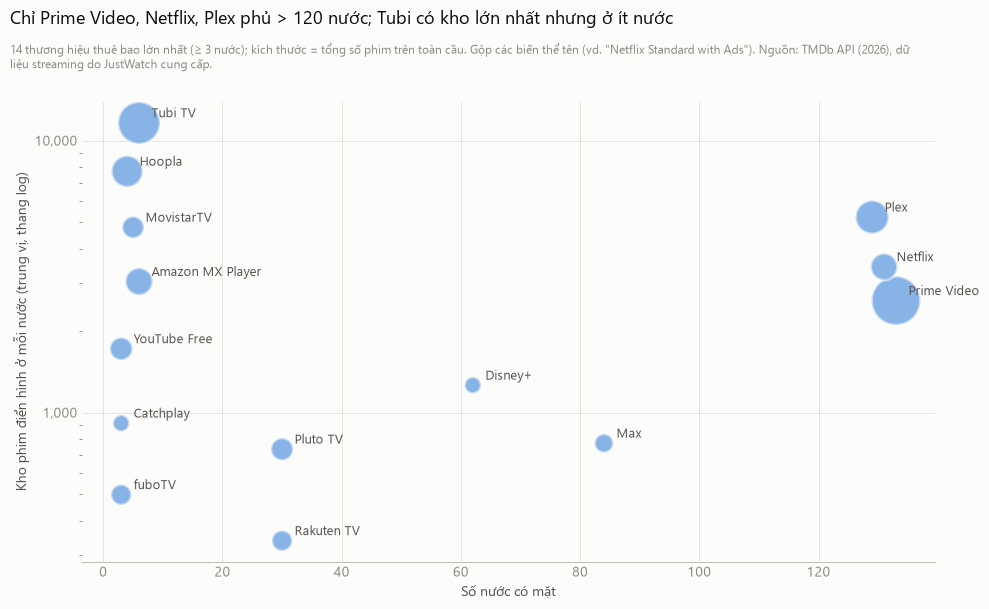

In [4]:
br = sub.groupby("brand").agg(countries=("country", "nunique"), movies=("imdb_id", "nunique"))
per_cc = sub.groupby(["brand", "country"])["imdb_id"].nunique().groupby("brand").median().rename("median_per_country")
br = br.join(per_cc)
br = br[br["countries"] >= 3].nlargest(14, "movies")
fig, ax = plt.subplots(figsize=(10, 6.2))
V.style_axes(ax, grid="both")
ax.scatter(br["countries"], br["median_per_country"], s=br["movies"] / br["movies"].max() * 1200 + 40,
           color=V.BLUE, alpha=0.55, edgecolor=V.SURFACE, linewidth=2)
for name, r in br.iterrows():
    ax.annotate(name, xy=(r["countries"], r["median_per_country"]), xytext=(9, 4), textcoords="offset points",
                color=V.INK2, fontsize=9)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(V.fmt_int))
ax.set_xlabel("Số nước có mặt")
ax.set_ylabel("Kho phim điển hình ở mỗi nước (trung vị, thang log)")
V.titles(fig, "Chỉ Prime Video, Netflix, Plex phủ > 120 nước; Tubi có kho lớn nhất nhưng ở ít nước",
         f"14 thương hiệu thuê bao lớn nhất (≥ 3 nước); kích thước = tổng số phim trên toàn cầu. "
         f"Gộp các biến thể tên (vd. \"Netflix Standard with Ads\"). {SRC}")
V.save(fig, FOLDER, "02_brand_reach_vs_depth")

**Nhận xét.** Chỉ **Prime Video, Netflix, Plex** có mặt ở > 120 nước. **Tubi** (miễn phí có quảng cáo) có kho phim lớn nhất nhưng chỉ ở vài nước. Disney+ và Max phủ 60–85 nước với kho nhỏ hơn. Có hai chiến lược: **phủ rộng toàn cầu** vs **kho sâu tại vài thị trường**.

## 3. Người xem tiếp cận phim hợp pháp bằng cách nào?

  wrote plots\3_tmdb_streaming\03_access_mode_by_country.png


WindowsPath('D:/dulieulon/plots/3_tmdb_streaming/03_access_mode_by_country.png')

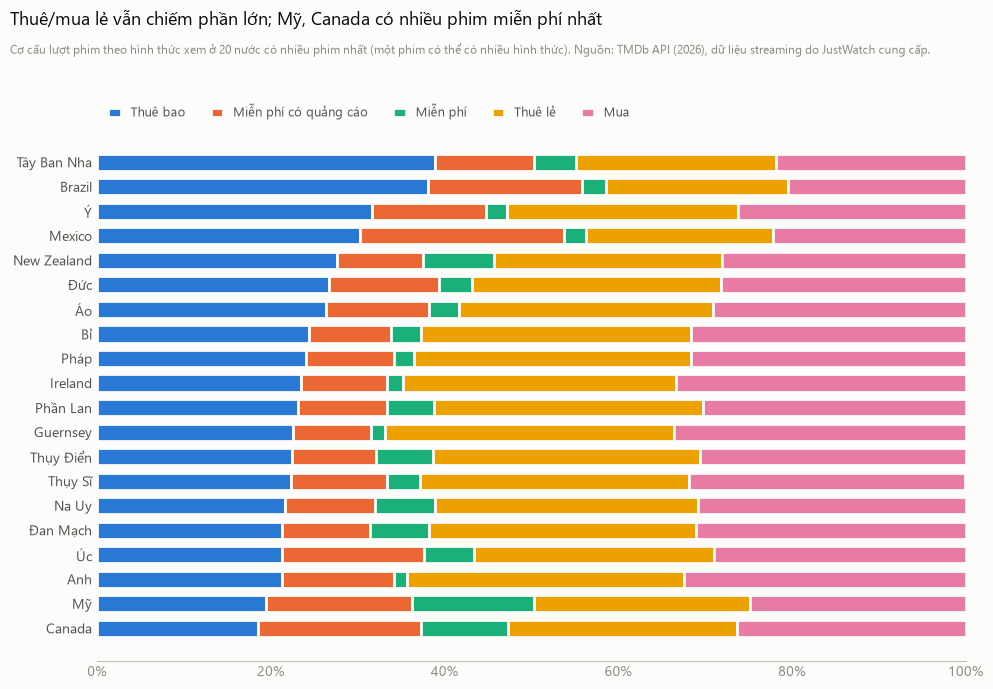

In [5]:
KIND = {"flatrate": "Thuê bao", "ads": "Miễn phí có quảng cáo", "free": "Miễn phí", "rent": "Thuê lẻ", "buy": "Mua"}
mix = wp.assign(k=wp["kind"].map(KIND)).groupby(["country", "k"])["imdb_id"].nunique().unstack(fill_value=0)
top_cc = wp.groupby("country")["imdb_id"].nunique().nlargest(20).index
mix = mix.loc[top_cc, list(KIND.values())]
mix = mix.div(mix.sum(axis=1), axis=0).sort_values("Thuê bao")
mix.index = [V.COUNTRY_VI.get(c, c) for c in mix.index]
fig, ax = plt.subplots(figsize=(10, 7))
V.style_axes(ax, grid=None)
left = np.zeros(len(mix))
for col, color in zip(mix.columns, V.CAT[:5]):
    ax.barh(mix.index, mix[col], left=left, color=color, edgecolor=V.SURFACE, linewidth=2, height=0.7, label=col)
    left += mix[col].values
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.tick_params(axis="y", colors=V.INK2)
ax.legend(ncol=5, loc="upper left", bbox_to_anchor=(0, 1.07), handlelength=1)
V.titles(fig, "Thuê/mua lẻ vẫn chiếm phần lớn; Mỹ, Canada có nhiều phim miễn phí nhất",
         f"Cơ cấu lượt phim theo hình thức xem ở 20 nước có nhiều phim nhất (một phim có thể có nhiều hình thức). {SRC}",
         extra=0.15)
V.save(fig, FOLDER, "03_access_mode_by_country")

**Nhận xét.** Ở hầu hết các nước, phần lớn lượt phim vẫn là **thuê/mua lẻ** (vàng + hồng). Tây Ban Nha, Brazil, Ý có tỷ lệ thuê bao cao nhất. **Mỹ và Canada** nổi bật với nhiều phim **miễn phí / miễn phí có quảng cáo** (Tubi, Pluto TV, Plex…) — mô hình FAST đang phát triển mạnh ở Bắc Mỹ.

## 4. Kho phim các nền tảng có trùng nhau không?

D:\dulieulon\src\viz_style.py:84: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 1 - head / h))


  wrote plots\3_tmdb_streaming\04_us_catalog_upset.png


WindowsPath('D:/dulieulon/plots/3_tmdb_streaming/04_us_catalog_upset.png')

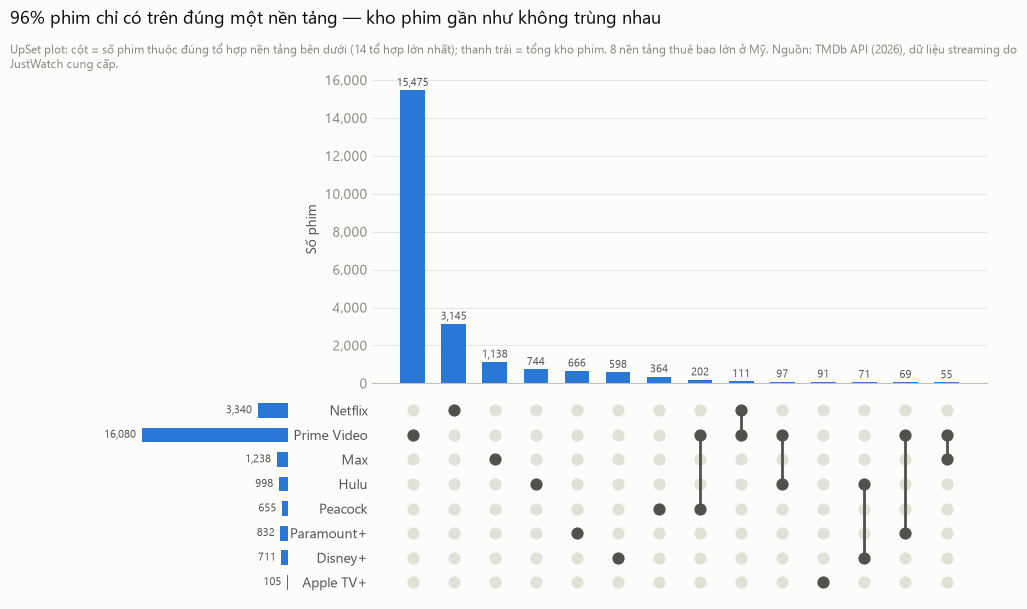

In [6]:
US_BRANDS = ["Netflix", "Prime Video", "Max", "Hulu", "Peacock", "Paramount+", "Disney+", "Apple TV+"]
us = sub[(sub["country"] == "US") & sub["brand"].isin(US_BRANDS)]
sets = us.groupby("imdb_id")["brand"].apply(lambda s: tuple(sorted(set(s), key=US_BRANDS.index)))
combo = sets.value_counts().head(14)
size = us.groupby("brand")["imdb_id"].nunique().reindex(US_BRANDS)
fig = plt.figure(figsize=(11, 6.8))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 4], height_ratios=[3, 2], wspace=0.22, hspace=0.04)
ax_bar = fig.add_subplot(gs[0, 1])
ax_mat = fig.add_subplot(gs[1, 1], sharex=ax_bar)
ax_size = fig.add_subplot(gs[1, 0], sharey=ax_mat)
x = np.arange(len(combo))
ax_bar.bar(x, combo.values, width=0.6, color=V.BLUE)
for xi, v in zip(x, combo.values):
    ax_bar.annotate(f"{v:,}", xy=(xi, v), xytext=(0, 3), textcoords="offset points", ha="center", color=V.INK2, fontsize=8)
V.style_axes(ax_bar)
ax_bar.tick_params(labelbottom=False)
ax_bar.set_ylabel("Số phim")
ax_bar.yaxis.set_major_formatter(FuncFormatter(V.fmt_int))
for yi, b in enumerate(US_BRANDS):
    ax_mat.scatter(x, [yi] * len(x), s=60, color=V.GRID, zorder=1)
for xi, c in enumerate(combo.index):
    ys = [US_BRANDS.index(b) for b in c]
    ax_mat.plot([xi] * len(ys), ys, color=V.INK2, linewidth=2, zorder=2)
    ax_mat.scatter([xi] * len(ys), ys, s=60, color=V.INK2, zorder=3)
ax_mat.set_yticks(range(len(US_BRANDS)))
ax_mat.set_yticklabels(US_BRANDS, color=V.INK2)
ax_mat.invert_yaxis()
for side in ("top", "right", "bottom", "left"):
    ax_mat.spines[side].set_visible(False)
ax_mat.tick_params(labelbottom=False, labelleft=True, length=0)
ax_size.barh(range(len(US_BRANDS)), size.values, color=V.BLUE, height=0.6)
ax_size.invert_xaxis()
ax_size.tick_params(axis="y", labelleft=False, labelright=False, length=0)
for yi, v in enumerate(size.values):
    ax_size.annotate(f"{v:,}", xy=(v, yi), xytext=(-4, 0), textcoords="offset points", ha="right", va="center",
                     color=V.INK2, fontsize=8)
for side in ("top", "left", "right"):
    ax_size.spines[side].set_visible(False)
ax_size.set_xticks([])
ax_size.spines["bottom"].set_visible(False)
excl = combo[[len(c) == 1 for c in combo.index]].sum() / sets.size
V.titles(fig, f"{excl:.0%} phim chỉ có trên đúng một nền tảng — kho phim gần như không trùng nhau",
         f"UpSet plot: cột = số phim thuộc đúng tổ hợp nền tảng bên dưới (14 tổ hợp lớn nhất); thanh trái = tổng kho phim. "
         f"8 nền tảng thuê bao lớn ở Mỹ. {SRC}")
V.save(fig, FOLDER, "04_us_catalog_upset")

**Nhận xét.** Gần như **không trùng**: ~96% phim chỉ có trên đúng một trong 8 nền tảng thuê bao lớn ở Mỹ. Tổ hợp nhiều nền tảng nhất (Prime Video + Peacock) chỉ ~200 phim. Muốn xem đủ phim, người xem phải đăng ký **nhiều dịch vụ cùng lúc** — đây là sự "phân mảnh" thường được nhắc tới như một động cơ của việc xem lậu (sẽ quay lại ở phần 3).

## 5. Mỗi nền tảng mạnh về thể loại nào?

  wrote plots\3_tmdb_streaming\05_genre_profile_by_brand.png


WindowsPath('D:/dulieulon/plots/3_tmdb_streaming/05_genre_profile_by_brand.png')

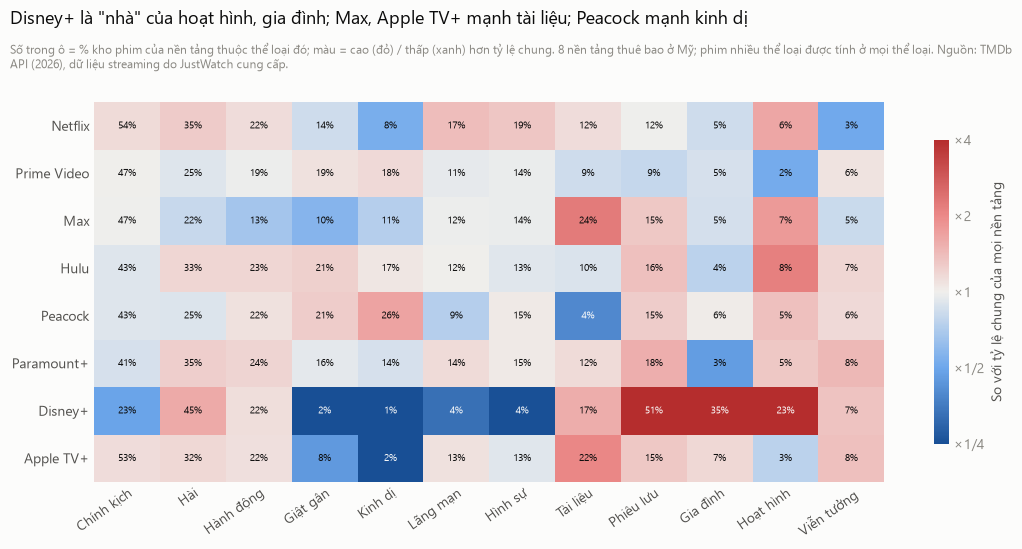

In [7]:
g = us.drop_duplicates(["imdb_id", "brand"]).merge(genres, on="imdb_id").dropna(subset=["genres"])
g = g.assign(genre=g["genres"].str.split(",")).explode("genre")
GEN = ["Drama", "Comedy", "Action", "Thriller", "Horror", "Romance", "Crime", "Documentary", "Adventure",
       "Family", "Animation", "Sci-Fi"]
share = g.pivot_table(index="brand", columns="genre", values="imdb_id", aggfunc="nunique").reindex(US_BRANDS)[GEN]
share = share.div(us.groupby("brand")["imdb_id"].nunique().reindex(US_BRANDS), axis=0)
overall = g.drop_duplicates(["imdb_id", "genre"]).groupby("genre")["imdb_id"].nunique()[GEN] / us["imdb_id"].nunique()
lift = share / overall
fig, ax = plt.subplots(figsize=(11, 5.6))
V.style_axes(ax, grid=None)
ax.spines["bottom"].set_visible(False)
from matplotlib.colors import TwoSlopeNorm
im = ax.imshow(np.log2(lift.values), cmap=V.DIV, norm=TwoSlopeNorm(0, -2, 2), aspect="auto")
ax.set_xticks(range(len(GEN)))
ax.set_xticklabels([V.GENRE_VI[x] for x in GEN], rotation=35, ha="right", rotation_mode="anchor", color=V.INK2)
ax.set_yticks(range(len(US_BRANDS)))
ax.set_yticklabels(US_BRANDS, color=V.INK2)
for i in range(lift.shape[0]):
    for j in range(lift.shape[1]):
        v = lift.values[i, j]
        ax.text(j, i, f"{share.values[i, j]:.0%}", ha="center", va="center", fontsize=7.5,
                color=V.SURFACE if abs(np.log2(v)) > 1.2 else V.INK)
cb = fig.colorbar(im, ax=ax, shrink=0.8, ticks=[-2, -1, 0, 1, 2])
cb.ax.set_yticklabels(["×1/4", "×1/2", "×1", "×2", "×4"], color=V.MUTED)
cb.outline.set_visible(False)
cb.set_label("So với tỷ lệ chung của mọi nền tảng", color=V.INK2)
V.titles(fig, "Disney+ là \"nhà\" của hoạt hình, gia đình; Max, Apple TV+ mạnh tài liệu; Peacock mạnh kinh dị",
         f"Số trong ô = % kho phim của nền tảng thuộc thể loại đó; màu = cao (đỏ) / thấp (xanh) hơn tỷ lệ chung. "
         f"8 nền tảng thuê bao ở Mỹ; phim nhiều thể loại được tính ở mọi thể loại. {SRC}")
V.save(fig, FOLDER, "05_genre_profile_by_brand")

**Nhận xét.** Mỗi nền tảng có "bản sắc" rõ: **Disney+** áp đảo hoạt hình (23%), gia đình (35%), phiêu lưu (51%) và gần như không có kinh dị/giật gân. **Max** và **Apple TV+** mạnh phim tài liệu (24%, 22%). **Peacock** mạnh kinh dị (26%). Netflix và Prime Video cân bằng hơn — đúng vai "siêu thị" phim.

## 6. Một phim trên Netflix có ở bao nhiêu nước?

  wrote plots\3_tmdb_streaming\06_netflix_country_spread.png


WindowsPath('D:/dulieulon/plots/3_tmdb_streaming/06_netflix_country_spread.png')

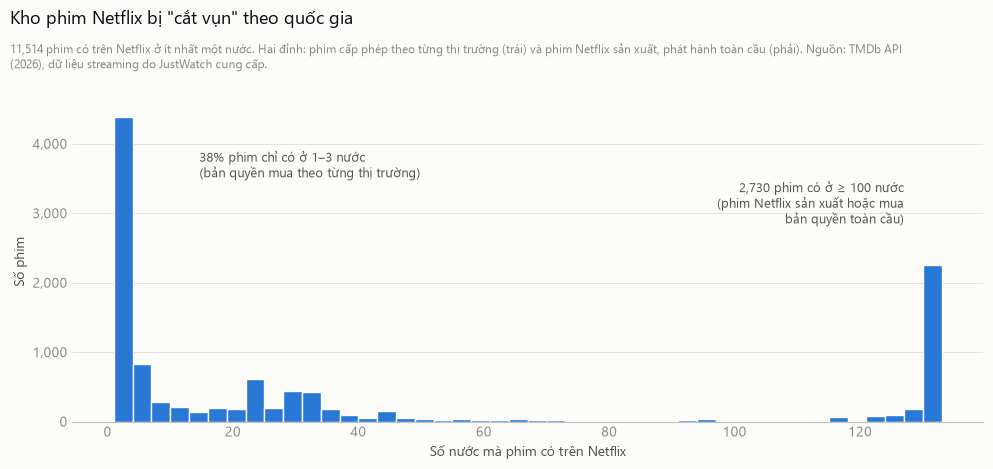

In [8]:
nf = sub[sub["brand"] == "Netflix"].groupby("imdb_id")["country"].nunique()
fig, ax = plt.subplots(figsize=(10, 4.8))
V.style_axes(ax)
ax.hist(nf, bins=np.arange(1, nf.max() + 4, 3), color=V.BLUE, edgecolor=V.SURFACE, linewidth=1)
glob = (nf >= 100).sum()
ax.annotate(f"{glob:,} phim có ở ≥ 100 nước\n(phim Netflix sản xuất hoặc mua\nbản quyền toàn cầu)", xy=(127, ax.get_ylim()[1] * 0.62),
            ha="right", color=V.INK2, fontsize=9)
ax.annotate(f"{(nf <= 3).mean():.0%} phim chỉ có ở 1–3 nước\n(bản quyền mua theo từng thị trường)", xy=(8, ax.get_ylim()[1] * 0.85),
            xytext=(30, 0), textcoords="offset points", va="top", color=V.INK2, fontsize=9)
ax.set_xlabel("Số nước mà phim có trên Netflix")
ax.set_ylabel("Số phim")
ax.yaxis.set_major_formatter(FuncFormatter(V.fmt_int))
V.titles(fig, "Kho phim Netflix bị \"cắt vụn\" theo quốc gia",
         f"{len(nf):,} phim có trên Netflix ở ít nhất một nước. Hai đỉnh: phim cấp phép theo từng thị trường (trái) "
         f"và phim Netflix sản xuất, phát hành toàn cầu (phải). {SRC}")
V.save(fig, FOLDER, "06_netflix_country_spread")

**Nhận xét.** Phân bố **hai đỉnh** rõ rệt: **38% phim chỉ có ở 1–3 nước** (bản quyền mua theo từng thị trường), trong khi **~2.700 phim có ở ≥ 100 nước** (phim Netflix sản xuất hoặc mua bản quyền toàn cầu). Cùng một thuê bao Netflix, kho phim ở mỗi nước rất khác nhau.

## Tóm tắt phần streaming (TMDb / JustWatch)

| Khía cạnh | Phát hiện chính |
|---|---|
| Địa lý | Kho phim hợp pháp lớn nhất ở Bắc Mỹ, Tây Âu, Úc |
| Nền tảng | Chỉ Prime Video, Netflix, Plex phủ > 120 nước |
| Hình thức | Thuê/mua lẻ vẫn chiếm phần lớn; Bắc Mỹ nhiều phim miễn phí có quảng cáo |
| Phân mảnh | ~96% phim chỉ có trên 1 nền tảng; kho Netflix khác nhau theo từng nước |
| Bản sắc | Disney+ = gia đình/hoạt hình; Max, Apple TV+ = tài liệu; Peacock = kinh dị |